# Phase 08 Part 1B — Trainer / Validation / Resume Contract
## + Historical Phase-09 Protocol Reconstruction

**Phase ID:** `phase_08_baseline_infrastructure`
**Part:** 1B
**Model:** Gemini 3.1 Pro High
**Project Root:** `D:\Softfors\jup` · **Kernel:** `jup-venv`

**Active manifest:** `phase4_v3` · **Frozen taxonomy:** `kub_size_clean_v3_v1`

> This notebook **reconstructs** the historical Phase-09 protocol and audits the
> trainer/checkpoint/resume contract. It performs **no scientific training** and
> never reads TEST content.

## 2. Scope / Governance

| Rule | Value |
|---|---|
| Historical results | labelled `HISTORICAL_v2` (`manifest_version = phase4_v2`) |
| TEST image/mask reads | **0** |
| TEST metrics / visualizations | **0** |
| Full scientific training | **NONE** |
| Checkpoint selection split | VAL only |
| Early stopping split | VAL only |
| Phase 09 | **NOT started** |
| Phase-13/14 test debt | documented, **not repaired** |

Historical v2 metrics are **not** rewritten as clean-v3 results.

In [1]:
import json, sys, tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use('Agg')
from IPython.display import Image as IPImage, display

PROJECT_ROOT = Path(r'D:\Softfors\jup')
CODE_DIR = PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_08_baseline_infrastructure' / 'code'
TABLES = PROJECT_ROOT / 'reports' / 'tables'
AUDITS = PROJECT_ROOT / 'reports' / 'audits'
FIGDIR = PROJECT_ROOT / 'reports' / 'figures' / 'phase08_baseline_infrastructure'
sys.path.insert(0, str(PROJECT_ROOT)); sys.path.insert(0, str(CODE_DIR))
import phase08b_protocol_audit as p8b

from src.training.trainer import EarlyStopping, Trainer
from src.utils.run_lock import acquire_lock, release_lock, inspect_lock, ExperimentLockError
from src.utils import config as cfgmod

print('torch :', torch.__version__)
print('manifest:', p8b.MANIFEST_VERSION_CLEAN, '| taxonomy:', p8b.TAXONOMY_ID)

torch : 2.6.0+cu124
manifest: phase4_v3 | taxonomy: kub_size_clean_v3_v1


## 3. Accepted Part-1A Contracts

Preserved from Part 1A (not redesigned here): `mask > 0` foreground, 1 input
channel, aspect-preserving resize + centre pad, nearest mask interpolation,
target sizes {256,512,768,1024}, CUDA-required device, AMP supported,
TRAIN stochastic / VAL deterministic, TEST locked.

## 4. Historical Phase-09 Source Audit

The checkpoint directory is the primary experiment-level provenance source.
Precedence: (1) config saved with the checkpoint, (2) trainer/model source,
(3) checkpoint metadata/history, (4) Phase-10 loop, (5) notebook/audit, (6) prose.

In [2]:
prov = p8b.audit_checkpoint_artifacts()
p8b.write_table(prov, 'phase08_phase09_checkpoint_artifact_provenance.csv')
display(prov[['artifact','kind','bytes','precedence_rank','sha256']])

,artifact,kind,bytes,precedence_rank,sha256
0,best.pt,checkpoint,93300670,3,a32d7fff1e019a179ef011795b6be8ee98ab548831f790...
1,latest.pt,checkpoint,93303994,3,2b535401e7db95469b39a62bd6b6df51e0e298c32d0004...
2,latest_interrupted_corrupt_20260914T115813.pt,checkpoint,93298746,3,daf5c823e4d8598230bfe74ea29b2c1a068fc4f9f7b5b0...
3,history.csv,history,11352,3,1012c73b2d51b9c7cde2512ee404978c722a5baea07dad...
4,summary.json,summary,4562,3,8beb5d9ed6b88da2d5464110a46dce7d9a8438a8afe8bd...
5,training.log,log,10047,5,a96d1b86ff150361dd037fa78410c17b966aad168bb82f...
6,resume_console.log,log,5256,5,37cbf6e77f98786b1c9eb0e253442409f981b07ddcbaf7...
7,resume_error.log,log,1752,5,e6bfcf207ab745c9ae4473250ba32a653ede22fdeacf8a...
8,unet_baseline.yaml,config,1051,1,9b8392f833c6f5350ae8780b24dae2afee1221e814f451...
9,phase10_baselines.yaml,config,1525,1,8501646965be04c84f674abecc905922119d5b249810b8...


In [3]:
ck = p8b.phase09_checkpoint_metadata()
print('best.pt   :', {k: v for k, v in ck['best.pt'].items() if k != 'manifest_hashes'})
print()
print('latest.pt :', {k: v for k, v in ck['latest.pt'].items() if k != 'manifest_hashes'})
print()
print('SHA best  :', ck['best.pt']['sha256'])
print('SHA latest:', ck['latest.pt']['sha256'])

best.pt   : {'epoch': 47, 'global_step': 23265, 'best_validation_score': 0.7455300688743591, 'seed': 42, 'manifest_version': 'phase4_v2', 'taxonomy_id': None, 'model_name': 'unet', 'input_resolution': 512, 'threshold': 0.5, 'early_stopping_state': {'best': 0.7455300688743591, 'bad_epochs': 0, 'patience': 15, 'stopped': False}, 'history_len': 47, 'has_random_state': True, 'has_loader_generator_states': True, 'has_grad_scaler_state': True, 'has_scheduler_state': True, 'has_optimizer_state': True, 'sha256': 'a32d7fff1e019a179ef011795b6be8ee98ab548831f790a557726f32b38db8ec'}

latest.pt : {'epoch': 62, 'global_step': 30690, 'best_validation_score': 0.7455300688743591, 'seed': 42, 'manifest_version': 'phase4_v2', 'taxonomy_id': None, 'model_name': 'unet', 'input_resolution': 512, 'threshold': 0.5, 'early_stopping_state': {'best': 0.7455300688743591, 'bad_epochs': 15, 'patience': 15, 'stopped': True}, 'history_len': 62, 'has_random_state': True, 'has_loader_generator_states': True, 'has_grad_

### 4b. Precedence check — checkpoint-embedded config vs YAML

In [4]:
import yaml
ck_cfg = p8b.load_phase09_config()
yaml_cfg = yaml.safe_load(p8b.PHASE09_CONFIG.read_text(encoding='utf-8'))

def flat(d, pre=''):
    out = {}
    for k, v in (d or {}).items():
        key = f'{pre}{k}'
        if isinstance(v, dict): out.update(flat(v, key + '.'))
        else: out[key] = v
    return out
a, b = flat(ck_cfg), flat(yaml_cfg)
keys = sorted(set(a) | set(b))
diffs = [(k, a.get(k, '<absent>'), b.get(k, '<absent>')) for k in keys if a.get(k, '<absent>') != b.get(k, '<absent>')]
print(f'fields compared : {len(keys)}')
print(f'identical       : {len(keys) - len(diffs)}')
print(f'differing       : {len(diffs)}')
for k, va, vb in diffs:
    print(f'  DIFF {k}: checkpoint={va!r} yaml={vb!r}')
print()
print('MATERIAL SOURCE DISAGREEMENTS:', len(diffs))

fields compared : 42
identical       : 42
differing       : 0

MATERIAL SOURCE DISAGREEMENTS: 0


## 5. Historical Baseline Set

In [5]:
mapping = p8b.build_phase_model_mapping()
p8b.write_table(mapping, 'phase08_phase09_phase_model_mapping.csv')
display(mapping)
print()
print('Phase-09 clean-rerun scope models:', int(mapping['in_phase09_clean_rerun_scope'].sum()))
print('Phase 09 = TRAINING (UNet baseline only); Phase 10 = COMPARISON (3 extra models).')

,phase,model,experiment_id,role,in_phase09_clean_rerun_scope,evidence
0,9,unet,phase9_kub_unet_baseline_seed42_512,Phase-09 baseline TRAINING,True,scripts/training/train_kub_baseline.py defines...
1,10,attention_unet,phase10_kub_attention_unet_seed42_512,Phase-10 baseline COMPARISON,False,configs/kub/phase10_baselines.yaml models[0]
2,10,unetpp,phase10_kub_unetpp_seed42_512,Phase-10 baseline COMPARISON,False,configs/kub/phase10_baselines.yaml models[1]
3,10,deeplabv3plus,phase10_kub_deeplabv3plus_seed42_512,Phase-10 baseline COMPARISON,False,configs/kub/phase10_baselines.yaml models[2]



Phase-09 clean-rerun scope models: 1
Phase 09 = TRAINING (UNet baseline only); Phase 10 = COMPARISON (3 extra models).


## 6. Exact Protocol Matrix

One row per historical baseline protocol, with source config/trainer SHAs.

In [6]:
protocol = p8b.build_protocol_matrix()
p8b.write_table(protocol, 'phase08_phase09_historical_protocol_matrix.csv')
cols = ['experiment_id','architecture','input_channels','output_channels','resolution',
        'manifest_version','loss','optimizer','learning_rate','weight_decay','scheduler',
        'scheduler_step_timing','batch_size','amp','seed','max_epochs','checkpoint_metric',
        'early_stopping_patience','prediction_threshold','protocol_status']
display(protocol[cols].T)

,0,1,2,3
experiment_id,phase9_kub_unet_baseline_seed42_512,phase10_kub_attention_unet_seed42_512,phase10_kub_unetpp_seed42_512,phase10_kub_deeplabv3plus_seed42_512
architecture,standard_unet_4_stage,attention_unet_4_stage_additive_gates,unetpp_nested_4_level_no_deep_supervision,deeplabv3plus_resnet50_os16
input_channels,1,1,1,1
output_channels,1,1,1,1
resolution,512,512,512,512
manifest_version,phase4_v2,phase4_v2,phase4_v2,phase4_v2
loss,bce_dice,bce_dice,bce_dice,bce_dice
optimizer,AdamW,AdamW,AdamW,AdamW
learning_rate,0.0001,0.0001,0.0001,0.0001
weight_decay,0.0001,0.0001,0.0001,0.0001


In [7]:
p = protocol.iloc[0]
for k in ['experiment_id','architecture','model_key','input_channels','output_channels',
          'base_channels','resolution','manifest_version','loss','loss_parameters',
          'optimizer','learning_rate','weight_decay','scheduler','scheduler_parameters',
          'scheduler_step_timing','batch_size','gradient_accumulation_steps',
          'effective_batch_size','amp','seed','max_epochs','augmentation_policy',
          'checkpoint_metric','checkpoint_mode','checkpoint_improvement_rule',
          'early_stopping_patience','early_stopping_min_delta','prediction_threshold',
          'validation_aggregation','val_shuffle','val_augmentation','num_workers',
          'pin_memory','gradient_clipping']:
    print(f'{k:32s}: {p[k]}')

experiment_id                   : phase9_kub_unet_baseline_seed42_512
architecture                    : standard_unet_4_stage
model_key                       : unet
input_channels                  : 1
output_channels                 : 1
base_channels                   : 32
resolution                      : 512
manifest_version                : phase4_v2
loss                            : bce_dice
loss_parameters                 : bce_weight=0.5, dice_weight=0.5, dice_epsilon=1e-06
optimizer                       : AdamW
learning_rate                   : 0.0001
weight_decay                    : 0.0001
scheduler                       : CosineAnnealingLR
scheduler_parameters            : T_max=100
scheduler_step_timing           : per epoch, after train AND validation
batch_size                      : 4
gradient_accumulation_steps     : 1
effective_batch_size            : 4
amp                             : True
seed                            : 42
max_epochs                      : 100
aug

## 4b. Phase-10 Cross-Check (field by field)

Proving the Phase-10 loop matches Phase-09 semantics requires showing the actual
fields, not asserting equivalence.

In [8]:
cross = p8b.build_phase10_crosscheck()
p8b.write_table(cross, 'phase08_phase09_phase10_crosscheck.csv')
display(cross)
print()
print('fields compared     :', len(cross))
print('identical           :', int((cross['same_or_different'] == 'same').sum()))
print('different           :', int((cross['same_or_different'] == 'different').sum()))
print('MATERIAL differences:', int(cross['material'].sum()))

,field,phase09_value,phase10_value,same_or_different,material,source_kind,comment
0,input_resolution,512,512,same,False,config,identical
1,loss.name,bce_dice,bce_dice,same,False,config,identical
2,loss.bce_weight,0.5,0.5,same,False,config,identical
3,loss.dice_weight,0.5,0.5,same,False,config,identical
4,loss.dice_epsilon,0.000001,0.000001,same,False,config,identical
5,optimizer.name,AdamW,AdamW,same,False,config,identical
6,optimizer.learning_rate,0.0001,0.0001,same,False,config,identical
7,optimizer.weight_decay,0.0001,0.0001,same,False,config,identical
8,scheduler.name,CosineAnnealingLR,CosineAnnealingLR,same,False,config,identical
9,scheduler.max_epochs,100,100,same,False,config,identical



fields compared     : 34
identical           : 32
different           : 2
MATERIAL differences: 0


## 7. Trainer Lifecycle

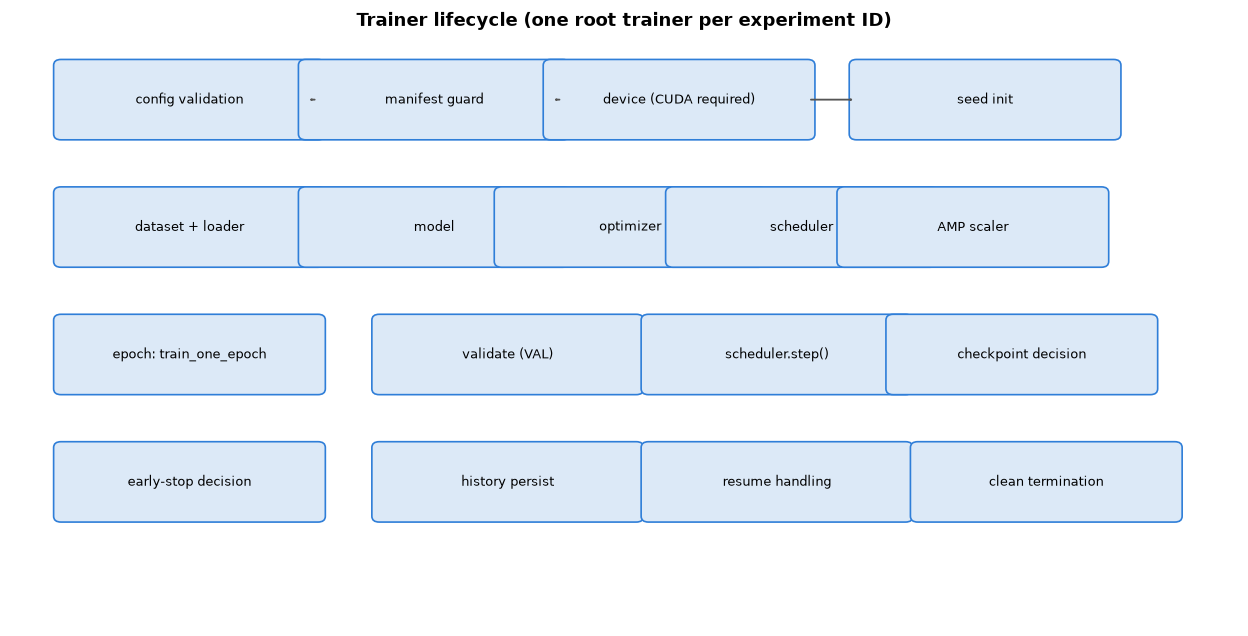

One root trainer per experiment ID; single-writer lock enforced by
src/utils/run_lock.py (active conflict fails loudly; stale recovery explicit).


In [9]:
display(IPImage(filename=str(FIGDIR / 'phase08b_trainer_lifecycle.png')))
print('One root trainer per experiment ID; single-writer lock enforced by')
print('src/utils/run_lock.py (active conflict fails loudly; stale recovery explicit).')

## 8. Training-Step Semantics

Ordering (from `src/training/trainer.py::train_one_epoch`):

`zero_grad(set_to_none=True)` → autocast forward → loss/accumulation →
scaled backward → on accumulation boundary: `scaler.step` → `scaler.update` →
`zero_grad`. No gradient clipping. No autonomous batch skipping.

In [10]:
src = (PROJECT_ROOT / 'src' / 'training' / 'trainer.py').read_text(encoding='utf-8')
checks = {
    'zero_grad first': 'self.optimizer.zero_grad(set_to_none=True)' in src,
    'autocast forward': 'torch.amp.autocast' in src,
    'scaled backward': 'self.scaler.scale(loss).backward()' in src,
    'scaler.step before update': src.find('scaler.step') < src.find('scaler.update'),
    'accumulation gating': '(index+1)%self.accumulation==0' in src,
    'no gradient clipping': 'clip_grad' not in src,
    'no batch skipping': 'continue' not in src,
}
for k, v in checks.items():
    print(f'  {k:30s}: {v}')

  zero_grad first               : True
  autocast forward              : True
  scaled backward               : True
  scaler.step before update     : True
  accumulation gating           : True
  no gradient clipping          : True
  no batch skipping             : True


## 9. Validation Aggregation

Canonical convention: **macro = unweighted mean of per-image metrics**.
Micro (global pixel aggregate) is also reported but is NOT used for checkpoint
selection. Hand-check examples below prove the semantics.

In [11]:
agg = p8b.build_validation_aggregation_contract()
p8b.write_table(agg, 'phase08_validation_aggregation_contract.csv')
display(agg)
print()
print('live macro check from the canonical implementation:',
      agg.attrs.get('live_macro_check'))
print()
print('VAL augmentation: OFF | VAL shuffle: FALSE | VAL deterministic: TRUE')

,example,per_image_dice,macro_mean_of_per_image,micro_global_pixel,macro_equals_micro,note
0,two_images_equal_area_one_perfect_one_empty,"1.0, 0.0",0.500000,0.500000,True,macro and micro differ; checkpoint selection u...
1,three_images_large_perfect_small_failure,"1.0, 1.0, 0.0",0.666667,0.952381,False,area-weighting makes micro >> macro
2,all_perfect,"1.0, 1.0",1.000000,1.000000,True,agree when every image is perfect



live macro check from the canonical implementation: 1.0

VAL augmentation: OFF | VAL shuffle: FALSE | VAL deterministic: TRUE


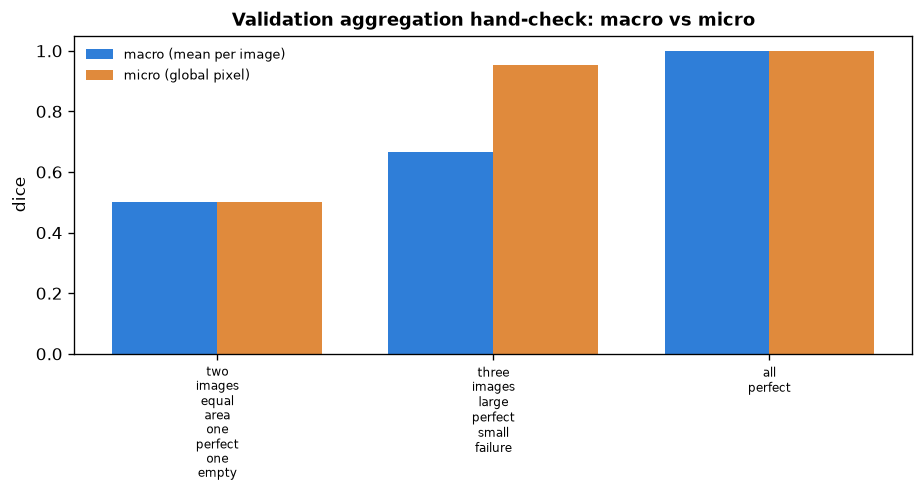

In [12]:
display(IPImage(filename=str(FIGDIR / 'phase08b_validation_aggregation_handcheck.png')))

## 10. Metric Threshold

In [13]:
print('prediction threshold (historical, unchanged):', p8b.load_phase09_config()['training']['threshold'])
print('used for: validation metrics AND qualitative panels')
print('Phase 08 does NOT retune this value.')

prediction threshold (historical, unchanged): 0.5
used for: validation metrics AND qualitative panels
Phase 08 does NOT retune this value.


## 11. Checkpoint-Selection Semantics

In [14]:
ckpt_contract = p8b.build_checkpoint_selection_contract()
p8b.write_table(ckpt_contract, 'phase08_checkpoint_selection_contract.csv')
display(ckpt_contract)

,item,value,source,note
0,metric,val_macro_dice,"config + trainer.validate()[""dice""]",macro mean of per-image dice at threshold 0.5
1,direction,higher_is_better (max),scripts/training/train_kub_baseline.py:183,
2,improvement_comparison,strict >,"val_info[""dice""] > best_val_dice",equality is NOT an improvement
3,minimum_delta,NaN,no delta configured,exact float comparison
4,tie_handling,tie -> not improved; best.pt NOT overwritten,strict > semantics,
5,best_checkpoint_semantics,written only on improvement,if improved: save best.pt,best.pt epoch=47
6,latest_checkpoint_semantics,written EVERY epoch,save latest.pt (unconditional),latest.pt epoch=62
7,selection_split,VAL only,trainer.validate requires VAL,TEST never used
8,test_usage,NEVER,verify_test_lock + allow_test=false,


## 12. Early-Stopping Semantics

In [15]:
es_contract = p8b.build_early_stopping_contract()
p8b.write_table(es_contract, 'phase08_early_stopping_contract.csv')
display(es_contract)

,item,value,note
0,implementation,src/training/trainer.py::EarlyStopping,"best init -inf, bad_epochs init 0"
1,patience,15,from config
2,improvement_rule,score > best (strict),"on improvement: best=score, bad_epochs=0"
3,no_improvement_rule,bad_epochs += 1,"any non-improvement increments, including ties"
4,tie_resets_counter,False,equal score counts as a bad epoch
5,stop_condition,bad_epochs >= patience,checked AFTER the epoch checkpoint is saved
6,minimum_delta,None,none configured
7,order_vs_checkpoint,"early_stopping.update() then save latest/best,...",the stopping epoch IS checkpointed
8,order_vs_scheduler,scheduler.step() happens before the early-stop...,per-epoch LR advance occurs even on the final ...
9,observed_final_state,"{'best': 0.7455300688743591, 'bad_epochs': 15,...",latest.pt early_stopping_state (bad_epochs == ...


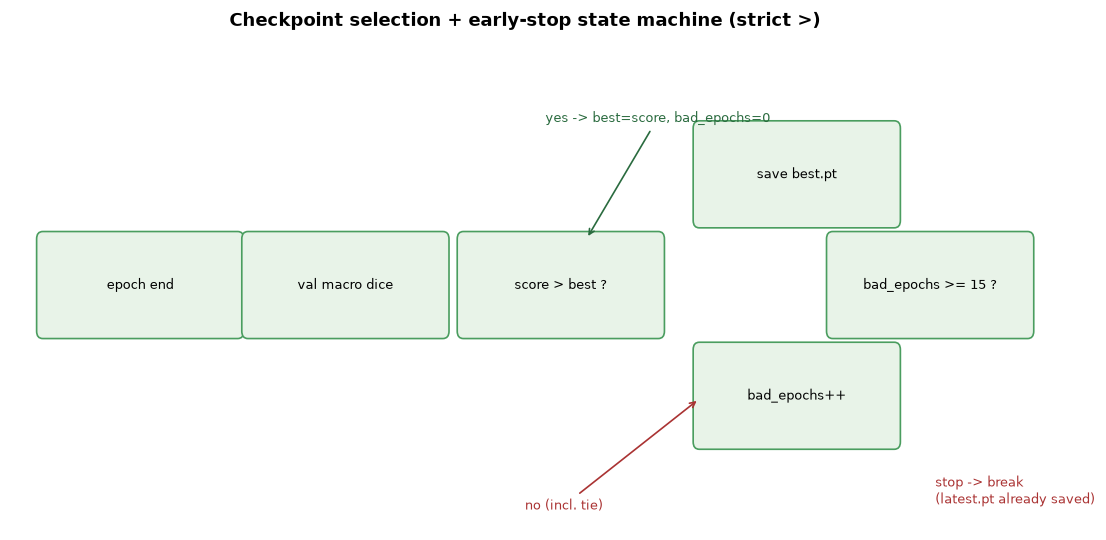

,epoch,score,bad_epochs,best,stop
0,1,0.50,0,0.5,False
1,2,0.50,1,0.5,False
2,3,0.40,2,0.5,False
3,4,0.60,0,0.6,False
4,5,0.60,1,0.6,False
5,6,0.55,2,0.6,False
6,7,0.55,3,0.6,True
7,8,0.55,4,0.6,True


In [16]:
display(IPImage(filename=str(FIGDIR / 'phase08b_checkpoint_state_machine.png')))
print()
# live boundary demonstration of the historical EarlyStopping
es = EarlyStopping(patience=3)
trace = []
for epoch, score in enumerate([0.50, 0.50, 0.40, 0.60, 0.60, 0.55, 0.55, 0.55], start=1):
    stop = es.update(score)
    trace.append({'epoch': epoch, 'score': score, 'bad_epochs': es.bad_epochs,
                  'best': es.best, 'stop': stop})
display(pd.DataFrame(trace))

## 13. Scheduler Semantics

In [17]:
sched_contract = p8b.build_scheduler_contract()
p8b.write_table(sched_contract, 'phase08_scheduler_contract.csv')
display(sched_contract)

,item,value,source,note
0,type,CosineAnnealingLR,scripts/training/train_kub_baseline.py:112,
1,parameters,T_max=100,"CosineAnnealingLR(optimizer, T_max=...)",no eta_min
2,step_frequency,per epoch,one scheduler.step() inside the epoch loop,
3,step_timing,after train_one_epoch AND after validate,"line 156, after line 154/155",not per batch
4,metric_driven,False,no ReduceLROnPlateau,
5,resume_state_required,True,scheduler_state saved/restored in checkpoint,
6,first_epoch_lr,initial lr (1e-4),step occurs at end of epoch 1,


## 14. History / Logging Contract

In [18]:
hist = pd.read_csv(PROJECT_ROOT / 'experiments' / p8b.PHASE09_EXP_ID / 'history.csv')
print('historical history.csv columns:', list(hist.columns))
print('rows:', len(hist))
display(hist.head(3))
print()
required = ['epoch','train_loss','val_loss','val_dice','val_iou','val_precision',
            'val_recall','learning_rate','epoch_seconds','peak_gpu_allocated',
            'peak_gpu_reserved']
print('all required per-epoch fields present:', all(c in hist.columns for c in required))
print('provenance fields required for clean-v3: experiment_id, manifest_version,')
print('taxonomy_id, seed (recorded alongside the history, not per row).')

historical history.csv columns: ['epoch', 'train_loss', 'val_loss', 'val_dice', 'val_iou', 'val_precision', 'val_recall', 'learning_rate', 'epoch_seconds', 'peak_gpu_allocated', 'peak_gpu_reserved']
rows: 62


,epoch,train_loss,val_loss,val_dice,val_iou,val_precision,val_recall,learning_rate,epoch_seconds,peak_gpu_allocated,peak_gpu_reserved
0,1,0.439578,0.425298,0.418775,0.332323,0.802409,0.441670,0.0001,195.664359,1695828480,1925185536
1,2,0.385187,0.382192,0.470158,0.384157,0.754831,0.545360,0.0001,72.375697,1695828480,1925185536
2,3,0.364937,0.378943,0.494332,0.403436,0.567020,0.566886,0.0001,72.136884,1695828480,1925185536



all required per-epoch fields present: True
provenance fields required for clean-v3: experiment_id, manifest_version,
taxonomy_id, seed (recorded alongside the history, not per row).


## 15. Experiment-ID / Single-Writer Contract

One experiment ID = one logical scientific run. Resume after crash/power loss/
interruption reuses the SAME ID; `_v2`/`_retry`/`_new` suffixes are not appended
merely because a run resumed.

In [19]:
with tempfile.TemporaryDirectory() as tmp:
    acquire_lock(tmp, 'demo_exp')
    st = inspect_lock(tmp)
    print('lock present:', st['present'], '| active:', st['active'], '| reason:', st['reason'])
    try:
        acquire_lock(tmp, 'demo_exp')
        print('ERROR: second trainer should have been refused')
    except ExperimentLockError as e:
        print('second trainer refused loudly:', type(e).__name__)
    # simulate a dead owner -> stale, explicit recovery
    import json
    from src.utils.run_lock import lock_path
    payload = json.loads(lock_path(tmp).read_text()); payload['pid'] = 999999999
    lock_path(tmp).write_text(json.dumps(payload))
    st2 = inspect_lock(tmp)
    print('after owner death -> active:', st2['active'], '| stale:', st2['stale'])
    rec = acquire_lock(tmp, 'demo_exp', recover_stale=True)
    print('stale recovered explicitly:', rec['recovered_stale_lock'])
    release_lock(tmp, force=True)

lock present: True | active: True | reason: owner process alive


second trainer refused loudly: ExperimentLockError
after owner death -> active: False | stale: True
stale recovered explicitly: True


## 16. Checkpoint / Resume Contract

In [20]:
resume_contract = p8b.build_resume_contract()
p8b.write_table(resume_contract, 'phase08_resume_contract.csv')
display(resume_contract)

,item,value,note
0,resume_source,latest.pt,best.pt used for final eval only
1,start_epoch,"state[""epoch""] + 1","continues, no repeat"
2,experiment_id,reused unchanged,hardcoded exp_id; no _v2/_retry suffixes on re...
3,manifest_guard_on_resume,manifest_version AND hashes must match,raises RuntimeError otherwise
4,model_state,True,load_state_dict
5,optimizer_state,True,
6,scheduler_state,True,
7,grad_scaler_state,True,AMP scaler
8,epoch,True,
9,best_metric,True,best_validation_score


## 17. Resume-Equivalence Probe

**INFRASTRUCTURE_TEST_ONLY** — synthetic data, no scientific claim.
Path A runs N steps continuously; Path B runs K steps, checkpoints, destroys the
objects, restores, then runs the remaining N-K steps.

In [21]:
probe = p8b.resume_equivalence_probe()
for k in ['label','device','steps','split_at','losses_identical','max_loss_abs_diff',
          'lr_schedule_identical','parameters_identical','max_param_abs_diff',
          'restored_experiment_id','restored_manifest_version','restored_taxonomy_id',
          'restored_epoch','scientific_claim']:
    print(f'{k:28s}: {probe[k]}')
print()
print('losses A:', [round(x, 8) for x in probe['losses_continuous']])
print('losses B:', [round(x, 8) for x in probe['losses_resumed']])

label                       : INFRASTRUCTURE_TEST_ONLY
device                      : cpu
steps                       : 6
split_at                    : 3
losses_identical            : True
max_loss_abs_diff           : 0.0
lr_schedule_identical       : True
parameters_identical        : True
max_param_abs_diff          : 0.0
restored_experiment_id      : phase08_resume_probe
restored_manifest_version   : phase4_v3
restored_taxonomy_id        : kub_size_clean_v3_v1
restored_epoch              : 3
scientific_claim            : NONE

losses A: [0.72215092, 0.72089607, 0.71884644, 0.71635991, 0.71376103, 0.71120632]
losses B: [0.72215092, 0.72089607, 0.71884644, 0.71635991, 0.71376103, 0.71120632]


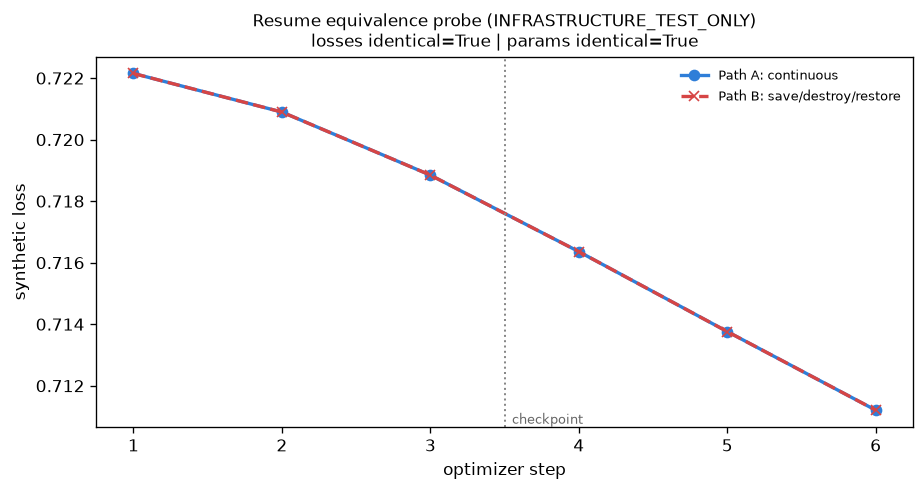

In [22]:
display(IPImage(filename=str(FIGDIR / 'phase08b_resume_equivalence_trace.png')))

## 18. Config Validation

In [23]:
t = cfgmod.config_template()
v = cfgmod.validate_experiment_config(t, require_all=True)
print('template with <REQUIRED> placeholders -> valid:', v['valid'], '(expected False)')
print('placeholder fields:', len(v['placeholder_fields']))
print()
full = {k: 'v' for k in cfgmod.REQUIRED_SCIENTIFIC_FIELDS}
full['manifest_version'] = 'phase4_v3'
print('complete config -> valid:', cfgmod.validate_experiment_config(full)['valid'])
missing = dict(full); missing.pop('loss')
print('missing loss -> valid:', cfgmod.validate_experiment_config(missing)['valid'])

template with <REQUIRED> placeholders -> valid: False (expected False)
placeholder fields: 15

complete config -> valid: True
missing loss -> valid: False


## 19. v2 → clean-v3 Protocol Diff

In [24]:
diff_df = p8b.build_protocol_diff(protocol.iloc[0].to_dict())
p8b.write_table(diff_df, 'phase08_phase09_v2_to_clean_v3_protocol_diff.csv')
display(diff_df[diff_df['same_or_changed'] == 'changed'])
print()
print('fields compared        :', len(diff_df))
print('changed fields         :', int((diff_df['same_or_changed'] == 'changed').sum()))
print('SCIENTIFICALLY MATERIAL:', int(diff_df['scientifically_material'].sum()))

,field,historical_v2,clean_v3_candidate,same_or_changed,change_reason,scientifically_material
0,experiment_id,phase9_kub_unet_baseline_seed42_512,phase9_kub_unet_baseline_seed42_512_clean_v3,changed,new logical run id,False
7,manifest_version,phase4_v2,phase4_v3,changed,authorized clean-v3 provenance,False
36,source_config,configs/kub/unet_baseline.yaml,<clean-v3 provenance>,changed,authorized provenance metadata,False
37,source_config_sha,9b8392f833c6f5350ae8780b24dae2afee1221e814f451...,<clean-v3 provenance>,changed,authorized provenance metadata,False
38,source_trainer,scripts/training/train_kub_baseline.py,<clean-v3 provenance>,changed,authorized provenance metadata,False
39,source_trainer_sha,c1c97d0a19445550f69291539c0090b492f186a535000e...,<clean-v3 provenance>,changed,authorized provenance metadata,False
42,checkpoint_best_sha,a32d7fff1e019a179ef011795b6be8ee98ab548831f790...,<clean-v3 provenance>,changed,authorized provenance metadata,False
43,checkpoint_latest_sha,2b535401e7db95469b39a62bd6b6df51e0e298c32d0004...,<clean-v3 provenance>,changed,authorized provenance metadata,False
44,protocol_status,VERIFIED,<clean-v3 provenance>,changed,authorized provenance metadata,False
45,historical_role,Phase-09 baseline (training),<clean-v3 provenance>,changed,authorized provenance metadata,False



fields compared        : 48
changed fields         : 12
SCIENTIFICALLY MATERIAL: 0


## 20. Candidate Clean-v3 Phase-09 Configs

In [25]:
cand = p8b.build_candidate_configs(ck_cfg)
p8b.write_table(cand, 'phase08_phase09_clean_v3_candidate_configs.csv')
paths = p8b.write_candidate_config_files(ck_cfg)
display(cand.T)
print()
print('candidate config file(s):', [str(p.relative_to(PROJECT_ROOT)) for p in paths])
print('status :', cand['candidate_status'].iloc[0])
print('executed:', cand['executed'].iloc[0])

,0
experiment_id,phase9_kub_unet_baseline_seed42_512_clean_v3
phase,9
dataset,KUB
manifest_version,phase4_v3
taxonomy_id,kub_size_clean_v3_v1
model_name,unet
input_channels,1
output_channels,1
base_channels,32
input_resolution,512



candidate config file(s): ['configs\\phase09_clean_v3\\phase09_unet_baseline_clean_v3.yaml']
status : RECONSTRUCTED_AND_READY
executed: False


## 21. Pre-existing Unrelated Test Debt

In [26]:
debt = p8b.build_test_debt()
display(debt)
print()
print('None of these are required by Phase-09 baseline infrastructure.')
print('Disposition:', debt['disposition'].iloc[0])
print()
print('NOTE: `pytest tests/` never completes because test_phase14_part1.py hangs.')
print('Part 1B therefore uses scoped test files, not the full suite.')

,test_file,observed,affected_phase,module,required_by_phase09,disposition,module_git_modified
0,tests/test_phase14_part1.py,HANGS (never completes),Phase 14,Phase-14 regional/refiner work,False,DEFER_TO_AFFECTED_CLEAN_RERUN_PHASE,None
1,tests/test_predicted_roi.py,3 failures,Phase 13,src/inference/predicted_roi.py,False,DEFER_TO_AFFECTED_CLEAN_RERUN_PHASE,False
2,tests/test_kub_localizer.py,1 failure,Phase 13,src/models/kub_localizer.py,False,DEFER_TO_AFFECTED_CLEAN_RERUN_PHASE,False



None of these are required by Phase-09 baseline infrastructure.
Disposition: DEFER_TO_AFFECTED_CLEAN_RERUN_PHASE

NOTE: `pytest tests/` never completes because test_phase14_part1.py hangs.
Part 1B therefore uses scoped test files, not the full suite.


## 22. Limitations

- Protocol reconstruction is from historical artifacts; no historical run was re-executed.
- Historical v2 metrics remain `HISTORICAL_v2` and are not comparable to clean-v3 results.
- The resume probe is synthetic and CPU-based; it does not claim GPU bitwise determinism.
- Phase-13/14 test debt is documented, not repaired (out of scope, unrelated modules).
- Candidate configs are **not** executed and are **not** scientifically authorized.

## 23. Phase-08 Conclusion

The historical Phase-09 protocol is fully reconstructed with no material ambiguity:
the checkpoint-embedded config matches the YAML exactly (0 disagreements), the
Phase-09 baseline set is a single UNet model, and the Phase-10 loop reproduces the
same semantics field-for-field. Trainer, validation, checkpoint, early-stopping,
scheduler and resume semantics are explicit and tested. A clean-v3 candidate config
differs from the historical protocol only in authorized provenance fields.

## 24. Artifact Hashes

In [27]:
ledger = {
    'historical_phase09': {
        'experiment_id': p8b.PHASE09_EXP_ID,
        'checkpoint_dir': 'checkpoints/phase9_kub_unet_baseline_seed42_512',
        'config_sha': p8b.sha256_file(p8b.PHASE09_CONFIG),
        'best_sha': ck['best.pt']['sha256'],
        'latest_sha': ck['latest.pt']['sha256'],
    },
    'clean_v3': {'manifest_version': p8b.MANIFEST_VERSION_CLEAN,
                 'taxonomy_id': p8b.TAXONOMY_ID},
    'resume_probe_passed': bool(probe['losses_identical'] and probe['parameters_identical']),
    'test_content_reads': 0,
    'full_scientific_training_performed': False,
    'phase09_started': False,
}
print(json.dumps(ledger, indent=2))
print()
reg = p8b.final_table_registry(TABLES)
display(reg)
print('TABLE COUNT:', int(reg['exists'].sum()))

{
  "historical_phase09": {
    "experiment_id": "phase9_kub_unet_baseline_seed42_512",
    "checkpoint_dir": "checkpoints/phase9_kub_unet_baseline_seed42_512",
    "config_sha": "9b8392f833c6f5350ae8780b24dae2afee1221e814f4517196e931ad169bce53",
    "best_sha": "a32d7fff1e019a179ef011795b6be8ee98ab548831f790a557726f32b38db8ec",
    "latest_sha": "2b535401e7db95469b39a62bd6b6df51e0e298c32d00047465bc39ababd0ad61"
  },
  "clean_v3": {
    "manifest_version": "phase4_v3",
    "taxonomy_id": "kub_size_clean_v3_v1"
  },
  "resume_probe_passed": true,
  "test_content_reads": 0,
  "full_scientific_training_performed": false,
  "phase09_started": false
}



,table,exists,bytes,sha256
0,phase08_phase09_checkpoint_artifact_provenance...,True,2497,7527e6123962eb3994778da1fc70078049230cc6db4377...
1,phase08_phase09_historical_protocol_matrix.csv,True,4720,3ffab9d43fcbd72d04f63cc8325f34a4eb2397948544c9...
2,phase08_phase09_phase_model_mapping.csv,True,605,7a0d9333bd917c9994dc6d9de6edb1df3fbee1118ff241...
3,phase08_phase09_phase10_crosscheck.csv,True,2558,fde37c6f347365005d168122f3372412f333662a4a8474...
4,phase08_validation_aggregation_contract.csv,True,425,2096b299fa2c1f314c1b771d670885587b3d7ecb7e6a15...
5,phase08_checkpoint_selection_contract.csv,True,774,8b8a92af17383d2ac9707ea9aaba73c77c7070843f7dc3...
6,phase08_early_stopping_contract.csv,True,894,3a63e2f0759465ef45e2ddd58b84b45ea19a2fc60a02d9...
7,phase08_scheduler_contract.csv,True,518,3fa2376766b9004828e6b705fec988c37b9d6490e5c3ab...
8,phase08_resume_contract.csv,True,993,2235a0d342876869f0fa933f31ce456b09437356d34485...
9,phase08_phase09_v2_to_clean_v3_protocol_diff.csv,True,4870,7a5efadcb06a0be83b0b8f95b234f57289563c2641c6d4...


TABLE COUNT: 11


In [28]:
print('=' * 62)
print('PHASE 08 PART 1B — FINAL STATUS')
print('=' * 62)
print('HISTORICAL PHASE09 EXP ID :', p8b.PHASE09_EXP_ID)
print('PHASE09 BASELINE MODELS   : 1 (unet)')
print('PHASE10 CROSS-CHECK       : material differences =', int(cross['material'].sum()))
print('v2 -> clean-v3 MATERIAL   :', int(diff_df['scientifically_material'].sum()))
print('CANDIDATE CONFIG          :', cand['candidate_status'].iloc[0])
print('TEST CONTENT READS        : 0')
print('FULL SCIENTIFIC TRAINING  : NO')
print('PHASE 09 STARTED          : NO')
print('=' * 62)

PHASE 08 PART 1B — FINAL STATUS
HISTORICAL PHASE09 EXP ID : phase9_kub_unet_baseline_seed42_512
PHASE09 BASELINE MODELS   : 1 (unet)
PHASE10 CROSS-CHECK       : material differences = 0
v2 -> clean-v3 MATERIAL   : 0
CANDIDATE CONFIG          : RECONSTRUCTED_AND_READY
TEST CONTENT READS        : 0
FULL SCIENTIFIC TRAINING  : NO
PHASE 09 STARTED          : NO
